In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 

import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

import tensorflow as tf
from tensorflow.keras import Sequential, layers, optimizers
from tensorflow.keras.callbacks import EarlyStopping
from scikeras.wrappers import KerasClassifier

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.utils import class_weight
from sklearn.metrics import (
    make_scorer, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

from datatypes import CLEAN_SQF

random.seed(123)
np.random.seed(123)
tf.random.set_seed(123)

import absl.logging
absl.logging.set_verbosity(absl.logging.ERROR)

In [2]:
clean_df = pd.read_csv(CLEAN_SQF)

features = clean_df.columns.difference(["USE_OF_FORCE_FLAG"]).values
X = clean_df[features]
y = clean_df["USE_OF_FORCE_FLAG"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

In [ ]:
def build_model(input_dim, neural_width=32, neural_depth=1, learning_rate=0.01):
    model = Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    
    for _ in range(neural_depth):
        model.add(layers.Dense(neural_width, activation="relu", kernel_initializer="he_normal"))
        model.add(layers.BatchNormalization())
        model.add(layers.Dropout(0.3))
        
    model.add(layers.Dense(1, activation="sigmoid"))
    
    opt = optimizers.Adam(learning_rate=learning_rate)
    
    model.compile(loss="binary_crossentropy", optimizer=opt, metrics=["Recall"])
    return model

# Handle imbalance in dataset
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = {0: weights[0], 1: weights[1]}

# Initialize neural network model
nn = KerasClassifier(
    model=build_model,
    input_dim=X_train.shape[1],
    class_weight=class_weight_dict,
    neural_width=32,
    neural_depth=1,
    learning_rate=0.01,
    batch_size=32,
    epochs=100,
    callbacks=[EarlyStopping(monitor='loss', patience=5, restore_best_weights=True)],
    verbose=0,
    random_state=123
)

# Define how data should be split, using a specified seed
cv_split = KFold(n_splits=5, shuffle=True, random_state=123)

# Define parameter grid for hyperparameter tuning
param_grid = {
    "neural_width": [32, 64, 128],
    "neural_depth": [1, 2],
    "learning_rate": [0.01, 0.001],
    "batch_size": [32, 64]
}

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)
}

# Initialize GridSearchCV, with tuning based on recall (our primary metric)
grid_search = GridSearchCV(
    nn,
    param_grid=param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_split,
    verbose=0,
    return_train_score=True,
)

# Run GridSearchCV
grid_search.fit(X_train, y_train)

print(f"We evaluated 3 neural widths, 2 neural depths, 2 learning rates, and 2 batch sizes "
      f"across 5 cross-validation folds, totaling 120 experimental fits. "
      f"Using recall as our metric, the best hyperparameters were {grid_search.best_params_}, "
      f"which achieved a recall score of {grid_search.best_score_:.2f}.")

              precision    recall  f1-score   support

           0       0.87      0.53      0.66      4107
           1       0.29      0.70      0.41      1131

    accuracy                           0.57      5238
   macro avg       0.58      0.62      0.53      5238
weighted avg       0.74      0.57      0.60      5238



E0000 00:00:1779781892.564803 7114343 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


<Figure size 640x480 with 0 Axes>

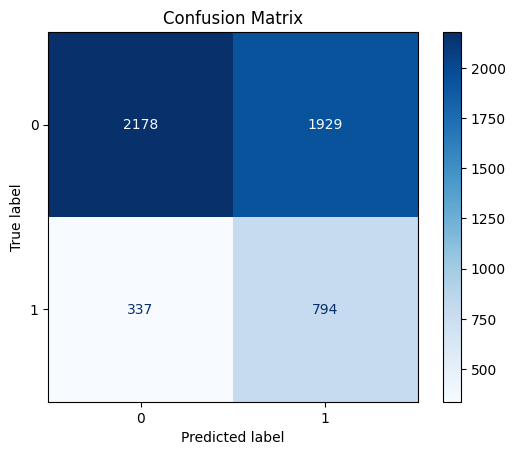

In [ ]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred))

# Create a confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)

plt.figure()
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()